# Figure 1 -- the parent sample over the DR4 scan law, and its colour--magnitude diagram (`star_sky_scanlaw_equatorial_density_cmd_absG_ms_full311`)

**Left:** a 10,000-star random subset of the simulated sample over the predicted DR4 per-epoch
*Gaia* scanning-law map (FoV transits per HEALPix pixel, without the $\sim$10\% expected data loss),
coloured by distance and scaled in marker area by stellar mass. **Right:** the colour--magnitude
diagram of the parent sample, $G_{\rm BP} - G_{\rm RP}$ against absolute $M_G$, as the fraction of
the sample per bin, with the Pecaut & Mamajek (2013) dwarf sequence dashed and the main-sequence
band $-1 \le \Delta M_G \le +1$ shaded. The stars inside the band are the ones the catalog
simulates.

Inputs: `catalog/data/stars.csv` (the generator's stage-1 star table, every star that survives the
Pecaut & Mamajek interpolation range), the GOST DR4 FoV-transit map and the Pecaut & Mamajek
table shipped with the generator, and `injected_solutions_0_companion.parquet` for the list of
stars actually simulated. The main-sequence label is the generator's own
(`epochalypse.stars.main_sequence_offset`), so the band drawn here is the cut the source list was
built with.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

import paperfig as pf          # paths, style, loaders and the shared figure machinery

pf.setup_style()               # Computer Modern, usetex -- the paper's typography
print("catalog :", pf.CATALOG)
print("paper figures         :", pf.PAPER_FIG_DIR)
print("supplementary figures :", pf.SUPP_FIG_DIR)

catalog : /Users/daniel/Desktop/epochalypse_catalog/catalog
paper figures         : /Users/daniel/Desktop/epochalypse_catalog/analysis/paper_figures
supplementary figures : /Users/daniel/Desktop/epochalypse_catalog/analysis/supplementary_figures


## 1. The parent sample

`stars.csv` holds every star within 500 pc whose absolute $G$ lies inside the Pecaut & Mamajek
interpolation range. The paper's *parent sample* additionally requires finite astrometry, a
positive parallax and mass, and **both** per-CCD noise terms, `sig_AL` and `sig_att_radec` (the
reported per-CCD error is $\sqrt{\sigma_{\rm att}^2 + \sigma_{\rm AL}^2}$, so a star missing either
has no reported *Gaia* error). The *simulated sample* is the parent sample restricted to the
main-sequence band; it is checked here against the control population's own list of sources.

In [2]:
stars = pf.star_columns()
print(f"{len(stars):,} rows in stars.csv")

in_parent = pf.parent_mask(stars)
offset = pf.main_sequence_offset(stars)
ms_class = pf.main_sequence_class(offset)
in_simulated = in_parent & (ms_class == "main_sequence")

stars["in_parent"], stars["cmd_class"], stars["delta_abs_G_ms"] = in_parent, ms_class, offset
stars["in_simulated"] = in_simulated
stars["distance_pc"] = 1000.0 / stars["parallax"]

n_no_sigal = int((~np.isfinite(stars["sig_AL"].to_numpy(float))).sum())
n_no_sigatt = int((np.isfinite(stars["sig_AL"].to_numpy(float))
                   & ~np.isfinite(stars["sig_att_radec"].to_numpy(float))).sum())
print(f"{in_parent.sum():,} in the parent sample  "
      f"({n_no_sigal:,} dropped for no sig_AL, {n_no_sigatt} for no sig_att_radec)")
print(f"{in_simulated.sum():,} of those on the main sequence "
      f"({100 * in_simulated.sum() / in_parent.sum():.1f}%) -> the simulated sample")

# the catalog's own list of simulated sources must be exactly this set
sim_ids = pf.simulated_ids()
assert set(sim_ids) == set(stars.loc[in_simulated, "gaia_source_id"].astype("int64")), \
    "the main-sequence + noise cut does not reproduce the simulated source list"
print(f"matches the {len(sim_ids):,} sources of the control population, star for star")

parent = stars[in_parent].copy()
simulated = stars[in_simulated].copy()

5,725,068 rows in stars.csv


5,724,572 in the parent sample  (482 dropped for no sig_AL, 14 for no sig_att_radec)
5,040,328 of those on the main sequence (88.0%) -> the simulated sample


matches the 5,040,328 sources of the control population, star for star


### Numbers for the text (Section 2)

In [3]:
for name, frame in (("parent sample", parent), ("simulated (main-sequence) sample", simulated)):
    hip = int(np.isfinite(frame["hip_id"].to_numpy(float)).sum())
    print(f"{name:34s}: {len(frame):,} stars; parallax {frame['parallax'].min():.2f}-{frame['parallax'].max():.2f} mas; "
          f"median G = {frame['phot_g_mean_mag_dr3'].median():.2f}; median distance {frame['distance_pc'].median():.0f} pc; "
          f"{hip:,} with Hipparcos ids; M_G {frame['abs_G'].min():.2f} to {frame['abs_G'].max():.2f}; "
          f"mass {frame['mass_interp'].min():.3f}-{frame['mass_interp'].max():.2f} Msun")
print(f"\nfaintest star in the sample: G = {parent['phot_g_mean_mag_dr3'].max():.3f}")

parent sample                     : 5,724,572 stars; parallax 2.00-546.98 mas; median G = 13.89; median distance 349 pc; 89,753 with Hipparcos ids; M_G -1.19 to 16.40; mass 0.078-5.40 Msun
simulated (main-sequence) sample  : 5,040,328 stars; parallax 2.00-546.98 mas; median G = 14.04; median distance 344 pc; 44,307 with Hipparcos ids; M_G -0.47 to 16.40; mass 0.078-4.12 Msun

faintest star in the sample: G = 16.000


### Spectral-type census (Section 2)

The catalog carries no spectral type, so each star is given the Pecaut & Mamajek dwarf type whose
tabulated $M_G$ is nearest its own `abs_G` -- the bins are the midpoints between consecutive
tabulated magnitudes along the same $M_G$-sorted track the mass and radius are interpolated on,
so the labels are consistent with `mass_interp`. M dwarfs are split into early (M0--M3.5),
mid (M4--M6.5) and late (M7 and later).

In [4]:
# nearest tabulated type in M_G, on the track mass_interp is interpolated along
_pm_track = pf.S.read_pecaut().dropna(subset=["M_G", "Msun", "R_Rsun"]).sort_values("M_G").reset_index(drop=True)
_pm_edges = (_pm_track["M_G"].to_numpy()[:-1] + _pm_track["M_G"].to_numpy()[1:]) / 2


def spectral_type(abs_g):
    """Pecaut & Mamajek dwarf type (e.g. 'K3V') with the nearest tabulated M_G."""
    return _pm_track["SpT"].to_numpy()[np.searchsorted(_pm_edges, np.asarray(abs_g, float))]


M_SUBCLASS_EDGES = (4.0, 7.0)                     # M0-M3.5 early, M4-M6.5 mid, M7+ late
SPT_GROUPS = ["O", "B", "A", "F", "G", "K", "M early (M0-M3.5)", "M mid (M4-M6.5)", "M late (M7+)"]


def spectral_group(spt):
    spt = pd.Series(spt)
    letter = spt.str[0]
    subtype = spt.str.extract(r"^[OBAFGKM](\d+(?:\.\d+)?)")[0].astype(float)
    m_group = np.select([subtype < M_SUBCLASS_EDGES[0], subtype < M_SUBCLASS_EDGES[1]],
                        [SPT_GROUPS[6], SPT_GROUPS[7]], default=SPT_GROUPS[8])
    return pd.Series(np.where(letter == "M", m_group, letter), index=spt.index)


for frame in (parent, simulated):
    frame["spt"] = spectral_type(frame["abs_G"].to_numpy(float))
    frame["spt_group"] = spectral_group(frame["spt"]).to_numpy()

census = pd.DataFrame({
    "simulated": simulated["spt_group"].value_counts().reindex(SPT_GROUPS, fill_value=0),
    "% of simulated": 100 * simulated["spt_group"].value_counts(normalize=True).reindex(SPT_GROUPS, fill_value=0),
    "parent": parent["spt_group"].value_counts().reindex(SPT_GROUPS, fill_value=0),
})
census["mass range [Msun]"] = [
    f"{g['mass_interp'].min():.3f}-{g['mass_interp'].max():.3f}" if len(g) else "-"
    for g in (simulated[simulated["spt_group"] == k] for k in SPT_GROUPS)]
print(census.to_string(formatters={"simulated": "{:,}".format, "parent": "{:,}".format,
                                   "% of simulated": "{:.2f}".format}))

_n = simulated["spt_group"].value_counts()
print(f"\nsimulated sample: FGK {_n.reindex(['F', 'G', 'K']).sum():,}; "
      f"all M {_n[_n.index.str.startswith('M')].sum():,}; "
      f"OBA {_n.reindex(['O', 'B', 'A'], fill_value=0).sum():,} "
      f"({100 * _n.reindex(['O', 'B', 'A'], fill_value=0).sum() / len(simulated):.2f}%)")

print("\nM dwarfs in the simulated sample, per tabulated subtype:")
_m = simulated.loc[simulated["spt"].str.startswith("M"), "spt"].value_counts()
print("  " + ", ".join(f"{k} {int(_m[k]):,}" for k in _pm_track["SpT"] if k in _m.index))

                  simulated % of simulated    parent mass range [Msun]
spt_group                                                             
O                         0           0.00         0                 -
B                     3,090           0.06    49,535       2.431-4.120
A                    48,660           0.97   130,548       1.680-2.430
F                   530,212          10.52   788,391       1.070-1.680
G                   930,288          18.46 1,022,742       0.890-1.070
K                 2,769,064          54.94 2,902,458       0.580-0.890
M early (M0-M3.5)   733,190          14.55   802,820       0.250-0.580
M mid (M4-M6.5)      25,796           0.51    28,023       0.092-0.250
M late (M7+)             28           0.00        55       0.078-0.091

simulated sample: FGK 4,229,564; all M 759,014; OBA 51,750 (1.03%)

M dwarfs in the simulated sample, per tabulated subtype:
  M0V 126,548, M0.5V 162,054, M1V 103,507, M1.5V 72,568, M2V 84,280, M2.5V 71,598, M3V 76,021

## 2. The subsample

The paper-wide down-selection: the 10,000 source ids with the smallest `blake2s(seed:id)` rank
(`paperfig.subsample_frame`, seed 20260824). Keyed on the id rather than a row index, it returns the
*same stars* out of any table that carries `gaia_source_id`, is invariant to row order, and is
nested in $n$. The sky map draws it from the **simulated** sample -- the stars the catalog holds;
set `SKYMAP_SAMPLE = "parent"` to draw the pre-cut sample instead.

In [5]:
from scipy import stats

N_SUBSAMPLE = 10_000
SKYMAP_SAMPLE = "simulated"                       # or "parent"
skymap_frame = {"simulated": simulated, "parent": parent}[SKYMAP_SAMPLE]
subset = pf.subsample_frame(skymap_frame, N_SUBSAMPLE)
print(f"{len(subset):,} stars selected out of {len(skymap_frame):,} ({SKYMAP_SAMPLE} sample)")

shuffled = skymap_frame.sample(frac=1.0, random_state=0)
assert set(pf.subsample_frame(shuffled, N_SUBSAMPLE).gaia_source_id) == set(subset.gaia_source_id)
assert set(pf.subsample_frame(skymap_frame, 1_000).gaia_source_id).issubset(set(subset.gaia_source_id))

# Is it representative? Two-sample KS against the full sample in the three quantities that
# govern astrometric detectability; at n = 10,000 the 5% noise floor is D ~ 0.0136.
rows = []
for name, col in (("distance [pc]", "distance_pc"), ("mass [Msun]", "mass_interp"), ("G [mag]", "phot_g_mean_mag_dr3")):
    d, p = stats.ks_2samp(subset[col], skymap_frame[col])
    rows.append({"quantity": name, "median (full)": np.median(skymap_frame[col]),
                 "median (subsample)": np.median(subset[col]), "KS D": d, "KS p": p})
pd.DataFrame(rows).set_index("quantity").round({"median (full)": 3, "median (subsample)": 3, "KS D": 4, "KS p": 3})

10,000 stars selected out of 5,040,328 (simulated sample)


,median (full),median (subsample),KS D,KS p
quantity,,,,
distance [pc],344.098,345.212,0.0056,0.908
mass [Msun],0.747,0.750,0.0114,0.149
G [mag],14.042,14.029,0.0076,0.602


## 3. The sky map

The GOST DR4 FoV-transit map underneath, `bone`, anchored at 40 transits (no pixel on the sky has
fewer than 42) and running to the map's own maximum of 311; the stars on top in clipped `plasma` by
distance to 500 pc, with marker area linear in stellar mass.

FoV transits per pixel: min 42, median 89, 99th pct 196, max 311


  wrote analysis/supplementary_figures/star_sky_scanlaw_equatorial_full311.pdf, analysis/supplementary_figures/star_sky_scanlaw_equatorial_full311.png


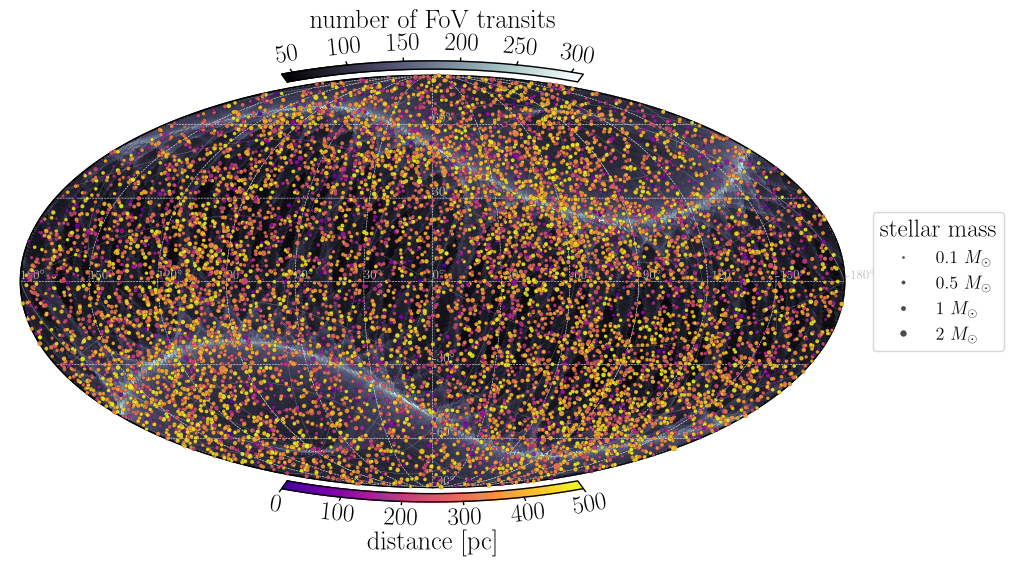

In [6]:
import healpy as hp
from matplotlib.colors import Normalize, LogNorm, LinearSegmentedColormap
from matplotlib.lines import Line2D

DISTANCE_VMAX = 500.0
STAR_CMAP_CLIP = 0.1
MASS_MARKER_FLOOR, MASS_MARKER_SCALE = 1.5, 8.0
MASS_LEGEND_MSUN = (0.1, 0.5, 1.0, 2.0)
TRANSIT_VMIN = 40.0
TRANSIT_SCALE = dict(vmax=311.0, ticks=[50, 100, 150, 200, 250, 300], tick_labels=None)   # "full311"

transit_map = hp.read_map(str(pf.C.GOST_FOV_MAP))
assert np.isfinite(transit_map).all()
assert transit_map.min() >= TRANSIT_VMIN
print(f"FoV transits per pixel: min {transit_map.min():.0f}, median {np.median(transit_map):.0f}, "
      f"99th pct {np.percentile(transit_map, 99):.0f}, max {transit_map.max():.0f}")
star_cmap = LinearSegmentedColormap.from_list(
    "plasma_clipped", plt.get_cmap("plasma")(np.linspace(STAR_CMAP_CLIP, 1.0, 256)))
star_norm = Normalize(vmin=0.0, vmax=DISTANCE_VMAX)


def marker_area(mass):
    return MASS_MARKER_FLOOR + MASS_MARKER_SCALE * np.asarray(mass)


def draw_skymap(fig, frame, *, sub=None, grat_fontsize=9, cbar_fontsize=18, legend="right"):
    """The scan-law panel with `frame`'s stars on top; returns its axes."""
    hp.visufunc.mollview(transit_map, fig=fig.number, coord="C", sub=sub, title="", cbar=False,
                         cmap="bone", notext=True, min=TRANSIT_VMIN, max=TRANSIT_SCALE["vmax"],
                         badcolor="white", bgcolor="white", flip="astro")
    ax = plt.gca()
    hp.visufunc.projscatter(frame["ra"].to_numpy(), frame["dec"].to_numpy(), lonlat=True, coord="C",
                            c=frame["distance_pc"].to_numpy(), s=marker_area(frame["mass_interp"].to_numpy()),
                            cmap=star_cmap, norm=star_norm, edgecolors="k", linewidths=0.12,
                            alpha=0.88, zorder=10)
    pf.decorate_skymap(ax, "Equatorial", "Ecliptic", "C", fontsize=grat_fontsize,
                       transit_ticks=TRANSIT_SCALE["ticks"], transit_tick_labels=TRANSIT_SCALE["tick_labels"])
    pf.add_curved_colorbar(ax, 0, DISTANCE_VMAX, star_cmap, side="bottom",
                           ticks=[0, 100, 200, 300, 400, 500], label="distance [pc]", fontsize=cbar_fontsize)
    if legend:
        handles = [Line2D([], [], marker="o", linestyle="none", markerfacecolor="0.3", markeredgecolor="k",
                          markeredgewidth=0.2, markersize=np.sqrt(marker_area(m)), label=rf"{m:g} $M_\odot$")
                   for m in MASS_LEGEND_MSUN]
        if legend == "right":
            ax.legend(handles=handles, title="stellar mass", loc="center left", bbox_to_anchor=(1.01, 0.5),
                      frameon=True, fontsize=13, title_fontsize=18)
        else:
            ax.legend(handles=handles, title="stellar mass", loc="upper center", bbox_to_anchor=(0.5, -0.015),
                      ncol=len(MASS_LEGEND_MSUN), frameon=True, fontsize=14, title_fontsize=16,
                      handletextpad=0.2, columnspacing=1.4, borderpad=0.5)
    return ax


fig = plt.figure(figsize=(10.0, 6.0))
draw_skymap(fig, subset)
pf.save(fig, "star_sky_scanlaw_equatorial_full311", dpi=200)
plt.show()

## 4. The colour--magnitude diagram

The parent sample binned in $G_{\rm BP} - G_{\rm RP}$ (0.05 mag) and absolute $M_G$ (0.2 mag),
coloured by the fraction of the sample per bin on a fixed log scale. $M_G = G + 5\log_{10}\varpi - 10$
is the catalog's own `abs_G`, the magnitude the mass and radius are interpolated in; neither it nor
the colour is corrected for extinction.

parent sample: 4,617 filled bins, fraction 1.7e-07-9.7e-03; 1,661 bins (0.062% of the sample) below the scale floor; 702 stars outside the frame


  wrote analysis/supplementary_figures/star_sky_scanlaw_equatorial_density_cmd_absG_full311.pdf, analysis/supplementary_figures/star_sky_scanlaw_equatorial_density_cmd_absG_full311.png


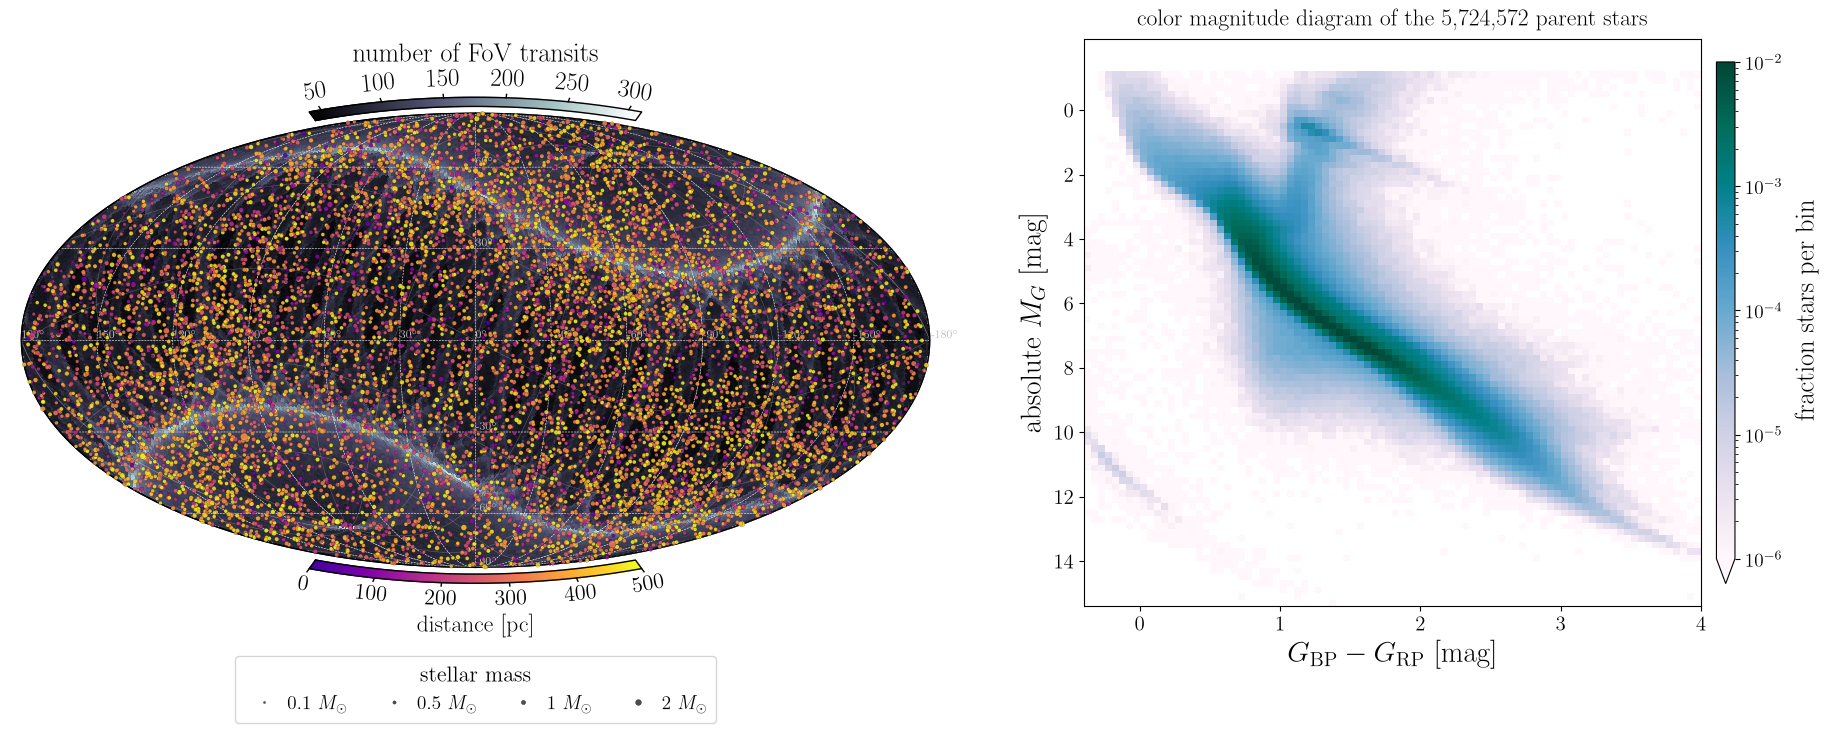

In [7]:
BPRP_LIM = (-0.4, 4.0)
CMD_N_BPRP = 88                                   # 0.05 mag in colour
cmd_bprp_bins = np.linspace(*BPRP_LIM, CMD_N_BPRP + 1)
DENSITY_CMAP = "PuBuGn"
CMD_FRACTION_VMIN = 1e-6
ABSG = dict(col="abs_G", lim=(-2.2, 15.4), n_bins=88, label=r"absolute $M_G$ [mag]",
            ticks=[0, 2, 4, 6, 8, 10, 12, 14], vmax=1e-2)
ABSG["bins"] = np.linspace(*ABSG["lim"], ABSG["n_bins"] + 1)
assert np.isclose(np.diff(ABSG["bins"])[0], 0.2)


def density_cmd_map(frame, label):
    """Fraction of `frame` per (bp_rp, M_G) bin; NaN where empty."""
    counts, _, _ = np.histogram2d(frame["bp_rp_dr3"].to_numpy(), frame[ABSG["col"]].to_numpy(),
                                  bins=(cmd_bprp_bins, ABSG["bins"]))
    fraction = np.where(counts > 0, counts / counts.sum(), np.nan)
    filled = fraction[np.isfinite(fraction)]
    assert filled.max() <= ABSG["vmax"], f"{label}: densest bin {filled.max():.2e} is above the scale"
    below = filled < CMD_FRACTION_VMIN
    print(f"{label}: {len(filled):,} filled bins, fraction {filled.min():.1e}-{filled.max():.1e}; "
          f"{below.sum():,} bins ({100 * filled[below].sum():.3f}% of the sample) below the scale floor; "
          f"{len(frame) - int(counts.sum()):,} stars outside the frame")
    return fraction


def draw_density_cmd(fig, ax, cmd_map, *, cbar_label_fontsize=19, axis_fontsize=21, tick_fontsize=15,
                     cbar_tick_fontsize=14):
    mesh = ax.pcolormesh(cmd_bprp_bins, ABSG["bins"], cmd_map.T, cmap=DENSITY_CMAP,
                         norm=LogNorm(vmin=CMD_FRACTION_VMIN, vmax=ABSG["vmax"]), rasterized=True)
    cbar = fig.colorbar(mesh, cax=ax.inset_axes([1.025, 0.04, 0.030, 0.92]), extend="min")
    cbar.set_label("fraction stars per bin", fontsize=cbar_label_fontsize, labelpad=10)
    cbar.ax.tick_params(labelsize=cbar_tick_fontsize)
    ax.set_xlim(*BPRP_LIM)
    ax.set_ylim(*ABSG["lim"])
    ax.set_ylabel(ABSG["label"], fontsize=axis_fontsize)
    ax.set_yticks(ABSG["ticks"])
    ax.tick_params(labelsize=tick_fontsize)
    return ax


parent_cmd = density_cmd_map(parent, "parent sample")

fig = plt.figure(figsize=(19.0, 7.0))
draw_skymap(fig, subset, sub=(1, 2, 1), grat_fontsize=8, cbar_fontsize=16, legend="below")
gs = fig.add_gridspec(1, 1, left=0.575, right=0.90, bottom=0.11, top=0.92)
ax = draw_density_cmd(fig, fig.add_subplot(gs[0]), parent_cmd)
ax.invert_yaxis()
ax.set_xticks([0.0, 1.0, 2.0, 3.0, 4.0])
ax.set_xlabel(r"$G_{\rm BP} - G_{\rm RP}$ [mag]", fontsize=21)
ax.set_title(rf"color magnitude diagram of the {pf.tex_num(len(parent))} parent stars", fontsize=17, pad=10)
pf.save(fig, "star_sky_scanlaw_equatorial_density_cmd_absG_full311", dpi=200)
plt.show()

## 5. The main-sequence band

Mass and radius are interpolated along the Pecaut & Mamajek dwarf sequence from $M_G$ alone, so a
subgiant or red-clump giant would be given the mass of whichever dwarf shares its $M_G$. The
catalog therefore simulates only the stars whose colour *and* magnitude together put them on the
dwarf sequence: the ridge $M_{G,\rm MS}(G_{\rm BP}-G_{\rm RP})$ from the same table, read the other
way, and the band $-1.0 \le \Delta M_G = M_G - M_{G,\rm MS} \le +1.0$. The bright edge leaves room
for an unresolved equal-mass binary ($0.75$ mag above the ridge) plus the width of the sequence;
only $\sim$1\% of the parent sample lies past the faint edge. Below: what the band keeps and drops,
on the parent sample.

In [8]:
MS_CLASSES = ["main_sequence", "above_ms", "below_ms", "outside_colour_range"]
counts = parent["cmd_class"].value_counts().reindex(MS_CLASSES, fill_value=0)
print(f"parent sample, band {pf.C.MS_BRIGHT_EDGE:+.1f} <= Delta M_G <= {pf.C.MS_FAINT_EDGE:+.1f}")
print(pd.DataFrame({"stars": counts, "% of parent": 100 * counts / len(parent)})
      .to_string(float_format=lambda v: f"{v:.2f}"))

# what is off the band, by colour and by distance from the ridge
_d, _x, _cls = parent["delta_abs_G_ms"], parent["bp_rp_dr3"], parent["cmd_class"]
_above, _below = _cls == "above_ms", _cls == "below_ms"
_wd = (parent["abs_G"] > 9.5) & (_x < 1.0)
_near = _d >= -3.0
groups = {
    "above: giants, red clump (dMG < -3)": _above & ~_near,
    "above: near band, bp_rp < 1.5 (subgiants, reddened dwarfs, triples)": _above & _near & (_x < 1.5),
    "above: near band, 1.5-2.0": _above & _near & (_x >= 1.5) & (_x < 2.0),
    "above: near band, bp_rp >= 2 (pre-MS M dwarfs, multiples)": _above & _near & (_x >= 2.0),
    "below: white-dwarf region": _below & _wd,
    "below: blue, M_G < 9.5 (hot subdwarfs)": _below & ~_wd & (_x < 0.3),
    "below: FGK, 0.3-1.5": _below & ~_wd & (_x >= 0.3) & (_x < 1.5),
    "below: K/M, bp_rp >= 1.5": _below & (_x >= 1.5),
}
print()
for name, m in groups.items():
    g = parent[m]
    print(f"  {name:70s} {len(g):>8,}   RUWE>1.4: {(g['ruwe_dr3'] > 1.4).mean():.2f}")
print(f"  {'on the band (reference)':70s} {int((_cls == 'main_sequence').sum()):>8,}   "
      f"RUWE>1.4: {(parent.loc[_cls == 'main_sequence', 'ruwe_dr3'] > 1.4).mean():.2f}")

parent sample, band -1.0 <= Delta M_G <= +1.0
                        stars  % of parent
cmd_class                                 
main_sequence         5040328        88.05
above_ms               622252        10.87
below_ms                59956         1.05
outside_colour_range     2036         0.04

  above: giants, red clump (dMG < -3)                                     110,396   RUWE>1.4: 0.19
  above: near band, bp_rp < 1.5 (subgiants, reddened dwarfs, triples)     371,266   RUWE>1.4: 0.27
  above: near band, 1.5-2.0                                                52,093   RUWE>1.4: 0.36
  above: near band, bp_rp >= 2 (pre-MS M dwarfs, multiples)                88,497   RUWE>1.4: 0.39
  below: white-dwarf region                                                 1,072   RUWE>1.4: 0.25
  below: blue, M_G < 9.5 (hot subdwarfs)                                      249   RUWE>1.4: 0.55
  below: FGK, 0.3-1.5                                                      49,690   RUWE>1.4: 0.92


  below: K/M, bp_rp >= 1.5                                                  8,945   RUWE>1.4: 0.43
  on the band (reference)                                                5,040,328   RUWE>1.4: 0.18


## 6. The paper figure

Section 4's figure with the band drawn on the CMD. The title counts the stars inside the band,
which are the stars every population of the catalog simulates.

ridge: 61 spectral types, B9V (-0.12) to M8.5V (5.10)


  wrote analysis/paper_figures/star_sky_scanlaw_equatorial_density_cmd_absG_ms_full311.pdf, analysis/paper_figures/star_sky_scanlaw_equatorial_density_cmd_absG_ms_full311.png


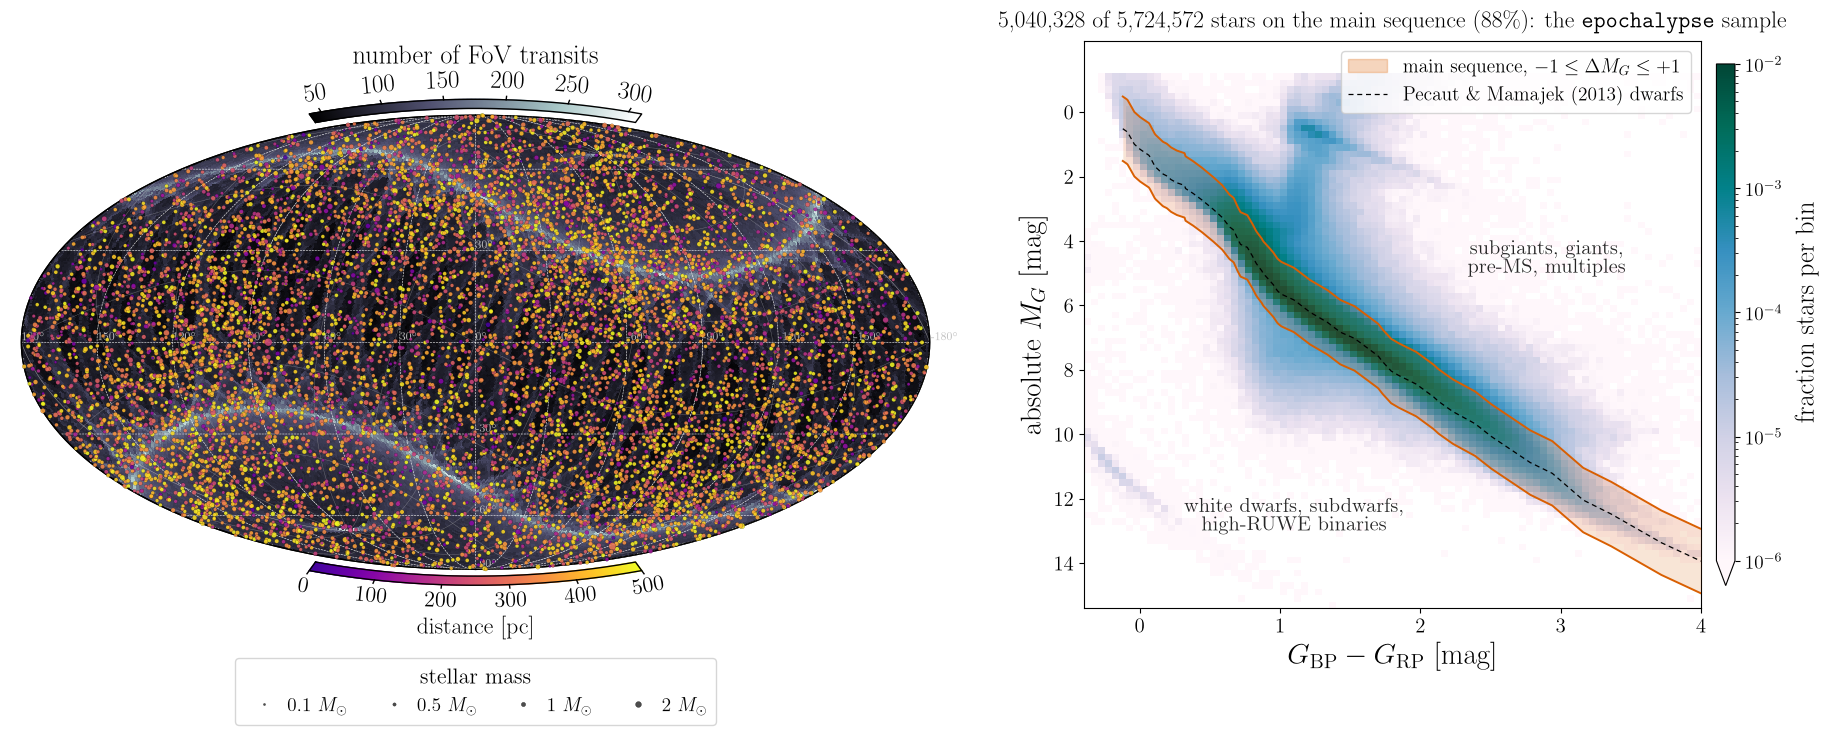

In [9]:
from matplotlib.patches import Patch

MS_BAND_COLOR, MS_BAND_ALPHA = "#d95f02", 0.16
MS_LABEL_ANCHOR_BPRP, MS_LABEL_OFFSET = 2.0, (0.9, 4.0)

# the ridge, from the generator's own table: B9V to M8.5V, where the colour turns over
_pm = pf.S.read_pecaut().dropna(subset=["Bp-Rp", "M_G"])
ms_ridge = _pm.loc[:_pm.index[_pm["SpT"] == pf.C.MS_RIDGE_LAST_SPT][0], ["SpT", "Bp-Rp", "M_G"]]
print(f"ridge: {len(ms_ridge)} spectral types, {ms_ridge.SpT.iloc[0]} ({ms_ridge['Bp-Rp'].iloc[0]:.2f}) "
      f"to {ms_ridge.SpT.iloc[-1]} ({ms_ridge['Bp-Rp'].iloc[-1]:.2f})")


def ms_ridge_abs_G(bp_rp):
    return np.interp(bp_rp, ms_ridge["Bp-Rp"], ms_ridge["M_G"], left=np.nan, right=np.nan)


def draw_ms_band(ax, fontsize=15):
    x = np.linspace(max(BPRP_LIM[0], ms_ridge["Bp-Rp"].iloc[0]), min(BPRP_LIM[1], ms_ridge["Bp-Rp"].iloc[-1]), 600)
    ridge = ms_ridge_abs_G(x)
    ax.fill_between(x, ridge + pf.C.MS_BRIGHT_EDGE, ridge + pf.C.MS_FAINT_EDGE, color=MS_BAND_COLOR,
                    alpha=MS_BAND_ALPHA, linewidth=0, zorder=3)
    for edge in (pf.C.MS_BRIGHT_EDGE, pf.C.MS_FAINT_EDGE):
        ax.plot(x, ridge + edge, color=MS_BAND_COLOR, lw=1.4, zorder=4)
    ax.plot(x, ridge, color="k", lw=0.9, ls=(0, (4, 3)), zorder=4)
    x0, y0 = MS_LABEL_ANCHOR_BPRP, float(ms_ridge_abs_G(MS_LABEL_ANCHOR_BPRP))
    dx, dy = MS_LABEL_OFFSET
    for sign, text in ((+1, "subgiants, giants,\npre-MS, multiples"),
                       (-1, "white dwarfs, subdwarfs,\nhigh-RUWE binaries")):
        ax.text(x0 + sign * dx, y0 - sign * dy, text, fontsize=fontsize, ha="center", va="center",
                color="0.15", zorder=5)
    handles = [Patch(facecolor=MS_BAND_COLOR, alpha=MS_BAND_ALPHA + 0.1, edgecolor=MS_BAND_COLOR,
                     label=rf"main sequence, ${pf.C.MS_BRIGHT_EDGE:+.0f} \le \Delta M_G \le {pf.C.MS_FAINT_EDGE:+.0f}$"),
               Line2D([], [], color="k", lw=0.9, ls=(0, (4, 3)), label=r"Pecaut \& Mamajek (2013) dwarfs")]
    ax.legend(handles=handles, loc="upper right", fontsize=fontsize - 1, frameon=True)


fig = plt.figure(figsize=(19.0, 7.0))
draw_skymap(fig, subset, sub=(1, 2, 1), grat_fontsize=8, cbar_fontsize=16, legend="below")
gs = fig.add_gridspec(1, 1, left=0.575, right=0.90, bottom=0.11, top=0.92)
ax = draw_density_cmd(fig, fig.add_subplot(gs[0]), parent_cmd)
draw_ms_band(ax)
ax.invert_yaxis()
ax.set_xticks([0.0, 1.0, 2.0, 3.0, 4.0])
ax.set_xlabel(r"$G_{\rm BP} - G_{\rm RP}$ [mag]", fontsize=21)
n_ms = len(simulated)
ax.set_title(rf"{pf.tex_num(n_ms)} of {pf.tex_num(len(parent))} stars on the main sequence "
             rf"({100 * n_ms / len(parent):.0f}\%): the \texttt{{epochalypse}} sample", fontsize=17, pad=10)
pf.save(fig, "star_sky_scanlaw_equatorial_density_cmd_absG_ms_full311", dpi=200, paper=True)
plt.show()